# 과제 1 — 시연 데이터 수집 및 Hub 업로드

**과제 내용**: 본인이 선택한 태스크(예: "큐브 집어 상자에 넣기")에 대해 **성공한 시연 50 에피소드**를 수집하고 Huggingface Hub에 업로드한다. 업로드 후 모든 에피소드를 검수해 문제가 없음을 확인한다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(assignments 폴더)에 `assignment_1.ipynb`로 올리고 저장소 링크를 제출한다. (이후 모든 과제도 동일하게 제출 예정)
- 데이터 수집은 **터미널에서** `lerobot-record`로 진행하고 이 노트북에는 확인 코드와 검수 결과를 작성한다.
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 데이터셋은 **public**으로 업로드한다. (private이면 웹 뷰어와 채점 코드로 확인할 수 없음)
- 데이터셋 이름은 자유롭게 정하되, **0. 제출 정보 셀**에 적은 repo_id **하나만** 채점 대상으로 한다.
- 실패한 시연, 중간에 잘린 시연, 카메라 영상이 비정상인 시연은 **다시 녹화**한다. 이 데이터는 이후 과제 학습에 그대로 쓰이며, ACT는 시연을 그대로 모방하므로 나쁜 시연은 성공률을 직접 떨어뜨린다.
- `--dataset.single_task`에 넣는 태스크 문장은 **영어로** 쓴다. (예: "Pick up the cube and put it in the box.") 과제 5에서 학습할 SmolVLA는 이 문장을 언어 입력으로 받는데, SmolVLA의 언어 모델은 영어로 학습되었다.
- GitHub 저장소에는 데이터 파일을 올리지 않는다. (데이터는 Huggingface Hub에 올리고 노트북 파일만 올린다.)
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

> **제출 전 필수 작업**: 이 노트북은 최종 업로드 dataset ID(`go234/cube-box_20261013_041703`), SO-101 구성, 카메라 장치와 녹화 명령을 반영한 초안입니다. 학번·이름, 카메라의 실제 배치 위치, 매 에피소드 물체 배치 방식, Hub 접근 여부와 메타데이터 출력, 50개 영상의 검수가 필요합니다. 검수표의 `?`를 실제 영상을 확인한 뒤 기록하세요.


In [1]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2020151003"
NAME = "고준협"
HF_USER = "go234"

DATASET = f"{HF_USER}/cube-box_20261013_041703"   # 업로드한 데이터셋 repo_id
TASK = "Pick up the cube and put it in the box."   # 녹화 시 --dataset.single_task에 넣은 영어 문장 그대로

print("학번/이름      :", STUDENT_ID, NAME)
print("데이터셋 repo_id:", DATASET)
print("데이터셋 링크  :", f"https://huggingface.co/datasets/{DATASET}")
print("태스크 설명    :", TASK)

학번/이름      : 2020151003 고준협
데이터셋 repo_id: go234/cube-box_20261013_041703
데이터셋 링크  : https://huggingface.co/datasets/go234/cube-box_20261013_041703
태스크 설명    : Pick up the cube and put it in the box.


In [2]:
# Hub 접근 확인 — "OK"가 나와야 한다
import json
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
try:
    repo_files = api.list_repo_files(DATASET, repo_type="dataset")
    print(f"OK  {DATASET}  (파일 {len(repo_files)}개)")
except Exception as e:
    repo_files = []
    print(f"FAIL  {DATASET} -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK  go234/cube-box_20261013_041703  (파일 11개)


## 1. 태스크 및 수집 환경

### 1-1. 태스크 정의
`[실제 수행 내용으로 수정]`
- **태스크 설명**: 테이블 위의 큐브를 집어 지정된 상자 안에 넣는다.
- **성공 조건**: 큐브가 상자 안에 완전히 들어가고, 그리퍼가 큐브를 놓은 상태로 에피소드가 끝난다.
- **시작 조건**: 로봇은 홈 자세에서 시작하고, 큐브와 상자는 지정된 작업 영역 안에 놓는다.

### 1-2. 수집 환경
`[실제 환경 정보 입력 — 임의로 기재하지 말 것]`
- 로봇 (모델 및 leader/follower 구성): SO-101 follower / SO-101 leader
- 카메라 (개수, 위치, 해상도): 2대, `/dev/video4` 및 `/dev/video6`, 각각 640×480 @ 25 fps. 카메라가 보이는 위치/각도는 실제 배치에 맞게 기입
- 물체 배치 방식 (매 에피소드 위치를 어떻게 바꿨는지): [실제 배치 및 에피소드별 위치 변경 방식을 입력]

사진이 있으면 `images/setup.jpg`로 올려 아래에 삽입한다. (선택)

![setup](images/setup.jpg)

### 1-3. 녹화 명령어
아래는 대화에서 사용한 녹화 명령이다. 실제로 실행한 명령과 다른 부분이 있으면 수정한다.

```bash
lerobot-record \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{cam1: {type: opencv, index_or_path: 4, width: 640, height: 480, fps: 25, fourcc: MJPG, backend: 200}, cam2: {type: opencv, index_or_path: 6, width: 640, height: 480, fps: 25, fourcc: MJPG, backend: 200}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --display_data=true \
  --dataset.repo_id=go234/cube-box \
  --dataset.private=false \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=50
```

## 2. 데이터셋 확인

In [3]:
# 메타데이터 확인 — 에피소드 수가 50이어야 한다
def load_json(repo_id, filename, repo_type="dataset"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

info = load_json(DATASET, "meta/info.json")
if info:
    n_ep = info.get("total_episodes")
    fps = info.get("fps")
    cams = [k for k in info.get("features", {}) if k.startswith("observation.images")]
    print("데이터셋 포맷 버전:", info.get("codebase_version"))
    print("에피소드 수       :", n_ep)
    print("총 프레임 수      :", info.get("total_frames"))
    print("fps               :", fps)
    print("카메라            :", cams)
    print("state 차원        :", info.get("features", {}).get("observation.state", {}).get("shape"))
    print("action 차원       :", info.get("features", {}).get("action", {}).get("shape"))
    print("\n에피소드 수 확인:", "통과" if n_ep == 50 else f"불일치 ({n_ep}개)")

info.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

데이터셋 포맷 버전: v3.0
에피소드 수       : 50
총 프레임 수      : 24423
fps               : 30
카메라            : ['observation.images.cam1', 'observation.images.cam2']
state 차원        : [6]
action 차원       : [6]

에피소드 수 확인: 통과


In [4]:
# 에피소드별 길이 불러오기 (v3.0: meta/episodes/*.parquet, v2.x: meta/episodes.jsonl)
ep_df = None
task_set = set()
try:
    pq_files = sorted(f for f in repo_files if f.startswith("meta/episodes/") and f.endswith(".parquet"))
    if pq_files:
        ep_df = pd.concat([pd.read_parquet(hf_hub_download(DATASET, f, repo_type="dataset")) for f in pq_files])
    elif "meta/episodes.jsonl" in repo_files:
        ep_df = pd.read_json(hf_hub_download(DATASET, "meta/episodes.jsonl", repo_type="dataset"), lines=True)
except Exception as e:
    print("에피소드 메타데이터 불러오기 실패:", type(e).__name__, e)

if ep_df is not None and "length" in ep_df.columns:
    ep_df = ep_df.sort_values("episode_index").reset_index(drop=True)
    lengths = ep_df[["episode_index", "length"]].copy()
    lengths["seconds"] = lengths["length"] / (fps or 30)
    med = lengths["length"].median()
    lengths["flag"] = lengths["length"].apply(
        lambda L: "짧음" if L < 0.5 * med else ("김" if L > 2.0 * med else ""))
    print(f"에피소드 길이: 평균 {lengths['seconds'].mean():.1f}s, "
          f"최소 {lengths['seconds'].min():.1f}s, 최대 {lengths['seconds'].max():.1f}s")

    # 태스크 문장 확인
    if "tasks" in ep_df.columns:
        task_set = {t for ts in ep_df["tasks"] for t in (ts if hasattr(ts, "__iter__") and not isinstance(ts, str) else [ts])}
        print("기록된 태스크 문장:", task_set)
        print("TASK와 일치       :", "통과" if task_set == {TASK} else "불일치 — 0번 셀의 TASK를 확인할 것")
        print("영어 문장         :", "통과" if all(t.isascii() for t in task_set) else "불일치 — task 문장은 영어로 쓴다")
else:
    lengths = None
    print("에피소드 길이 정보를 찾지 못함")

meta/episodes/chunk-000/file-000.parquet: reconstructing file:   0%|          |  0.00B /  235kB            

meta/episodes/chunk-000/file-000.parquet: downloading bytes:           |  0.00B            

에피소드 길이: 평균 16.3s, 최소 9.7s, 최대 32.2s
기록된 태스크 문장: {'Pick up the cube and put it in the box.'}
TASK와 일치       : 통과
영어 문장         : 통과


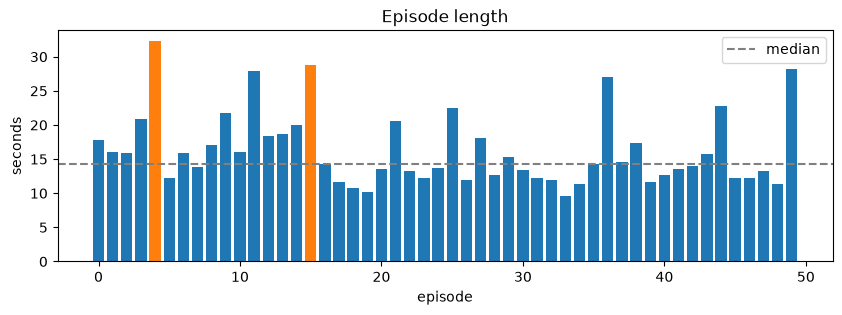

길이 이상 의심 에피소드: [4, 15]


In [5]:
# 에피소드 길이 그래프 — 중앙값의 0.5배 미만(빨강)이나 2배 초과(주황)는 잘리거나 머뭇거린 시연일 수 있으니 우선 검수
if lengths is not None:
    color_map = {"짧음": "tab:red", "김": "tab:orange", "": "tab:blue"}
    plt.figure(figsize=(10, 3))
    plt.bar(lengths["episode_index"], lengths["seconds"], color=lengths["flag"].map(color_map))
    plt.axhline(lengths["seconds"].median(), ls="--", c="gray", label="median")
    plt.xlabel("episode"); plt.ylabel("seconds"); plt.title("Episode length")
    plt.legend(); plt.show()

    flagged = lengths[lengths["flag"] != ""]
    print("길이 이상 의심 에피소드:", flagged["episode_index"].tolist() or "없음")

## 3. 검수

웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 데이터셋 repo_id를 넣고 **50개 에피소드를 모두 재생**하며 확인한다.

**확인 항목**
1. 1-1에서 정한 성공 조건대로 태스크가 끝까지 성공했는가
2. 동작 시작 전에 시작해 완료 후에 끝나는가 (중간에 잘리지 않았는가)
3. 모든 카메라 영상이 정상인가 (검은 화면, 멈춤, 끊김 없음)
4. state·action 그래프가 동작에 맞게 움직이는가 (평평한 직선이 아닌가)

### 3-1. 에피소드별 검수표
`[작성]` 아래 셀의 `?`를 `O`(이상 없음) 또는 `X`(문제 있음)로 바꾸고, 필요하면 `|` 뒤에 메모를 적는다.
최종 제출 데이터셋은 **모든 에피소드가 `O`**여야 한다. `X`가 있으면 재녹화 후 다시 검수한다. 영상 50개를 실제로 확인하기 전에는 결과를 기입하거나 모두 `O`로 표시하지 않는다.

In [6]:
REVIEW = """
 0 | ? |
 1 | ? |
 2 | ? |
 3 | ? |
 4 | ? |
 5 | ? |
 6 | ? |
 7 | ? |
 8 | ? |
 9 | ? |
10 | ? |
11 | ? |
12 | ? |
13 | ? |
14 | ? |
15 | ? |
16 | ? |
17 | ? |
18 | ? |
19 | ? |
20 | ? |
21 | ? |
22 | ? |
23 | ? |
24 | ? |
25 | ? |
26 | ? |
27 | ? |
28 | ? |
29 | ? |
30 | ? |
31 | ? |
32 | ? |
33 | ? |
34 | ? |
35 | ? |
36 | ? |
37 | ? |
38 | ? |
39 | ? |
40 | ? |
41 | ? |
42 | ? |
43 | ? |
44 | ? |
45 | ? |
46 | ? |
47 | ? |
48 | ? |
49 | ? |
"""

review_rows = []
for line in REVIEW.strip().splitlines():
    parts = [p.strip() for p in line.split("|")]
    review_rows.append({"episode": int(parts[0]), "result": parts[1],
                        "note": parts[2] if len(parts) > 2 else ""})
review_df = pd.DataFrame(review_rows)
print(review_df["result"].value_counts().to_string())
review_df[review_df["result"] != "O"]   # O가 아닌 행만 표시

result
?    50


,episode,result,note
0,0,?,
1,1,?,
2,2,?,
3,3,?,
4,4,?,
5,5,?,
6,6,?,
7,7,?,
8,8,?,
9,9,?,


### 3-2. 재녹화 기록
`[작성]` 수집·검수 과정에서 다시 녹화한 시연이 있었다면 몇 개를, 어떤 문제 때문에 다시 녹화했는지 적는다. (없으면 "없음")

-

## 4. 소감 및 과제 2 준비
`[작성]` 3~5문장으로 답한다.

**4-1.** 수집하면서 시연의 일관성을 유지하기 위해 신경 쓴 점은 무엇인가?

**4-2.** 이 데이터로 ACT를 학습했을 때 정책이 어려워할 것 같은 상황은 무엇이라고 예상하는가?

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [7]:
check_items = {
    "데이터셋 접근 가능 (public)": len(repo_files) > 0,
    "에피소드 50개": bool(info) and info.get("total_episodes") == 50,
    "검수표 50개 에피소드 모두 기재": sorted(review_df["episode"]) == list(range(50)),
    "검수 결과 모두 O": (review_df["result"] == "O").all(),
    "태스크 문장이 TASK와 일치하고 영어로 작성됨": task_set == {TASK} and all(t.isascii() for t in task_set),
    "검수표와 데이터셋 에피소드 수 일치": bool(info) and len(review_df) == info.get("total_episodes"),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] 데이터셋 접근 가능 (public)
[통과] 에피소드 50개
[통과] 검수표 50개 에피소드 모두 기재
[미흡] 검수 결과 모두 O
[통과] 태스크 문장이 TASK와 일치하고 영어로 작성됨
[통과] 검수표와 데이터셋 에피소드 수 일치

미흡 항목을 보완한 뒤 커밋할 것
